# Chest X-ray Pneumonia Classifier — Training Notebook

**Goal:** train a model that looks at a chest X-ray and says *Normal* or *Pneumonia*, then show **where** it looked (Grad-CAM).

**Run this in Google Colab with a free GPU:** `Runtime → Change runtime type → T4 GPU`, then run each cell from top to bottom (`Shift + Enter`).

Steps:
1. Install & import libraries
2. Load the data (PneumoniaMNIST, 224×224)
3. Look at the data
4. Build the data pipeline
5. Build the model (transfer learning with EfficientNetB0)
6. Train — phase 1 (frozen backbone) and phase 2 (fine-tuning)
7. Evaluate on the test set (sensitivity, specificity, AUC)
8. Explain predictions with Grad-CAM
9. Save the model for the web app

## 1. Install & import libraries

In [1]:
!pip install -q "medmnist>=3.0"

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from medmnist import PneumoniaMNIST
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))  # should show one GPU in Colab

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the data

PneumoniaMNIST is a cleaned, ready-split version of a public pediatric chest X-ray dataset (Kermany et al., 2018).
`size=224` gives full 224×224 images. The download (~ a few hundred MB) happens automatically the first time.

In [3]:
IMG_SIZE = 224
CLASS_NAMES = ["Normal", "Pneumonia"]

train_data = PneumoniaMNIST(split="train", download=True, size=IMG_SIZE)
val_data   = PneumoniaMNIST(split="val",   download=True, size=IMG_SIZE)
test_data  = PneumoniaMNIST(split="test",  download=True, size=IMG_SIZE)

X_train, y_train = train_data.imgs, train_data.labels.ravel()
X_val,   y_val   = val_data.imgs,   val_data.labels.ravel()
X_test,  y_test  = test_data.imgs,  test_data.labels.ravel()

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:5s}: images {X.shape}, Normal={np.sum(y==0)}, Pneumonia={np.sum(y==1)}")

100%|██████████| 214M/214M [00:43<00:00, 4.90MB/s]


train: images (4708, 224, 224), Normal=1214, Pneumonia=3494
val  : images (524, 224, 224), Normal=135, Pneumonia=389
test : images (624, 224, 224), Normal=234, Pneumonia=390


## 3. Look at the data

Always look at your images before training. Notice: there are about **3× more pneumonia images than normal** — the data is *imbalanced*. We will correct for that with class weights.

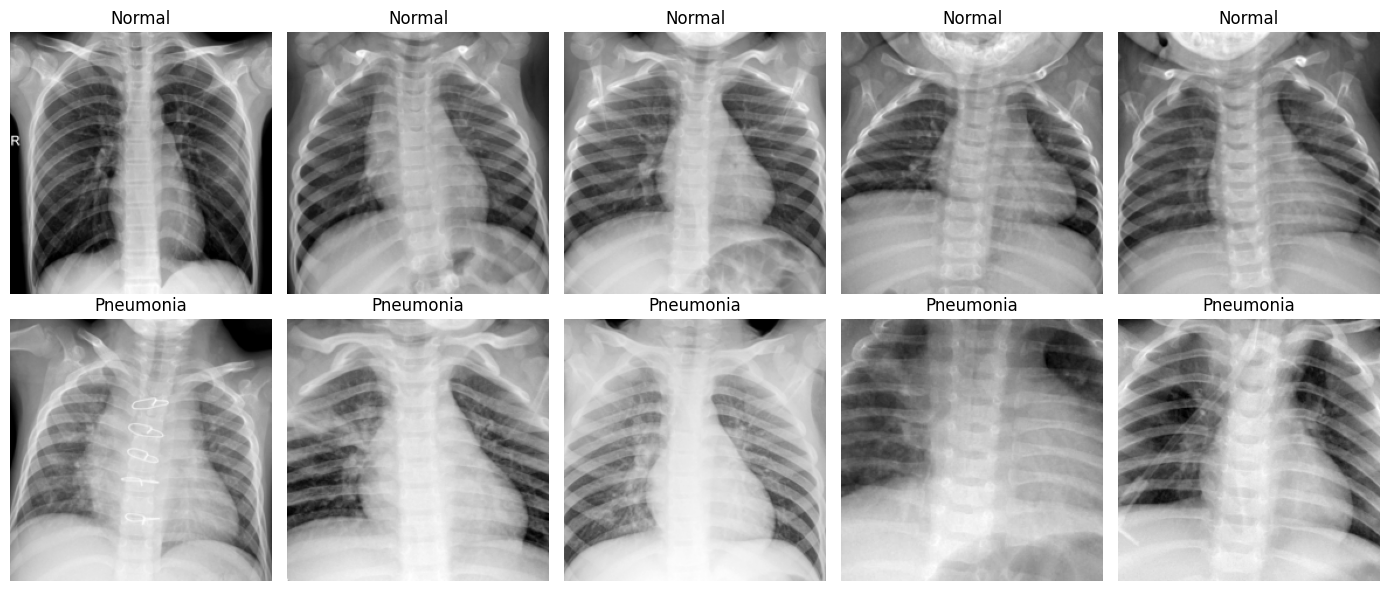

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, cls in enumerate([0, 1]):
    idx = np.where(y_train == cls)[0][:5]
    for col, i in enumerate(idx):
        axes[row, col].imshow(X_train[i], cmap="gray")
        axes[row, col].set_title(CLASS_NAMES[cls])
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("results/sample_images.png", dpi=120)
plt.show()

## 4. Build the data pipeline

- The pretrained network expects **3-channel (RGB)** images, so we copy the grey channel 3 times.
- **Augmentation** (small rotations, zooms, shifts) only on training images, so the model doesn't memorise them.
- Pixel values stay 0–255: EfficientNet in Keras does its own scaling inside the model.

In [5]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

augment = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
])

def to_rgb(x, y):
    x = tf.cast(x, tf.float32)[..., tf.newaxis]   # (224,224) -> (224,224,1)
    x = tf.image.grayscale_to_rgb(x)              # -> (224,224,3)
    return x, tf.cast(y, tf.float32)

def make_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).map(to_rgb, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=SEED)
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val, y_val)
test_ds  = make_dataset(X_test, y_test)

# Class weights: make mistakes on the smaller class (Normal) count more
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

Class weights: {0: np.float64(1.9390444810543657), 1: np.float64(0.6737263880938752)}


## 5. Build the model — transfer learning

Instead of training from zero, we start from **EfficientNetB0 pretrained on ImageNet** (it already knows edges, textures, shapes) and add a small "head" that outputs one number: the probability of pneumonia.

In [6]:
base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base.trainable = False  # phase 1: freeze the pretrained part

x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dropout(0.3)(x)
output = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
model = tf.keras.Model(base.input, output)

METRICS = [
    tf.keras.metrics.BinaryAccuracy(name="accuracy"),
    tf.keras.metrics.AUC(name="auc"),
    tf.keras.metrics.Recall(name="sensitivity"),
    tf.keras.metrics.Precision(name="precision"),
]
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=METRICS)
print("Trainable params:", sum(np.prod(w.shape) for w in model.trainable_weights))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable params: 1281


## 6a. Train — phase 1 (only the new head learns)

`EarlyStopping` stops when validation AUC stops improving; `ModelCheckpoint` keeps the best version.

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("models/pneumonia_model.keras", monitor="val_auc",
                                       mode="max", save_best_only=True),
]
history1 = model.fit(train_ds, validation_data=val_ds, epochs=10,
                     class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 116s 568ms/step - accuracy: 0.8564 - auc: 0.9397 - loss: 0.3502 - precision: 0.9578 - sensitivity: 0.8437 - val_accuracy: 0.9084 - val_auc: 0.9816 - val_loss: 0.2944 - val_precision: 0.9942 - val_sensitivity: 0.8817
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 58s 386ms/step - accuracy: 0.9085 - auc: 0.9705 - loss: 0.2318 - precision: 0.9758 - sensitivity: 0.8990 - val_accuracy: 0.8626 - val_auc: 0.9864 - val_loss: 0.3185 - val_precision: 1.0000 - val_sensitivity: 0.8149
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 59s 395ms/step - accuracy: 0.9142 - auc: 0.9758 - loss: 0.2057 - precision: 0.9792 - sensitivity: 0.9035 - val_accuracy: 0.8874 - val_auc: 0.9883 - val_loss: 0.2700 - val_precision: 1.0000 - val_sensitivity: 0.8483
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 58s 388ms/step - accuracy: 0.9206 - auc: 0.9777 - loss: 0.1932 - precision: 0.9771 - sensitivity: 0.9144 - val_accuracy: 0.9103 - val_auc: 0.9893 - val_loss: 0.2304 - val_precision: 0.9971 - val

## 6b. Train — phase 2 (fine-tuning)

Now we unfreeze the **top 40 layers** of EfficientNet and train with a **very small learning rate**, so the pretrained knowledge adapts gently to X-rays. BatchNorm layers stay frozen (standard practice).

In [8]:
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy", metrics=METRICS)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=10,
                     class_weight=class_weight, callbacks=callbacks)

Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 115s 573ms/step - accuracy: 0.9360 - auc: 0.9855 - loss: 0.1534 - precision: 0.9826 - sensitivity: 0.9302 - val_accuracy: 0.9351 - val_auc: 0.9923 - val_loss: 0.1964 - val_precision: 0.9972 - val_sensitivity: 0.9152
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 60s 397ms/step - accuracy: 0.9429 - auc: 0.9874 - loss: 0.1397 - precision: 0.9844 - sensitivity: 0.9379 - val_accuracy: 0.9389 - val_auc: 0.9928 - val_loss: 0.1753 - val_precision: 0.9972 - val_sensitivity: 0.9203
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 84s 412ms/step - accuracy: 0.9452 - auc: 0.9886 - loss: 0.1341 - precision: 0.9856 - sensitivity: 0.9399 - val_accuracy: 0.9618 - val_auc: 0.9933 - val_loss: 0.1184 - val_precision: 0.9946 - val_sensitivity: 0.9537
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 62s 409ms/step - accuracy: 0.9467 - auc: 0.9893 - loss: 0.1284 - precision: 0.9853 - sensitivity: 0.9422 - val_accuracy: 0.9447 - val_auc: 0.9922 - val_loss: 0.1608 - val_precision: 0.9972 - val

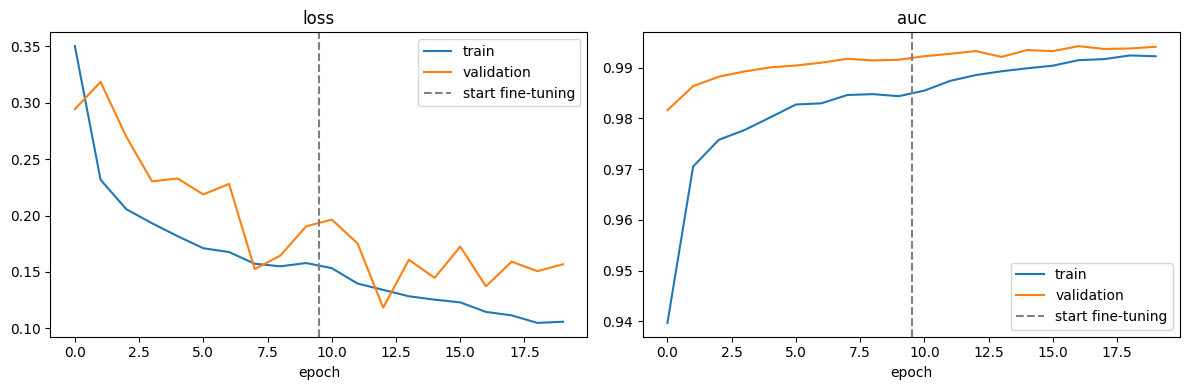

In [9]:
def plot_history(histories, metric):
    values = sum([h.history[metric] for h in histories], [])
    val_values = sum([h.history["val_" + metric] for h in histories], [])
    plt.plot(values, label="train")
    plt.plot(val_values, label="validation")
    plt.axvline(len(histories[0].history[metric]) - 0.5, color="gray", ls="--", label="start fine-tuning")
    plt.title(metric); plt.xlabel("epoch"); plt.legend()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plot_history([history1, history2], "loss")
plt.subplot(1, 2, 2); plot_history([history1, history2], "auc")
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=120); plt.show()

## 7. Evaluate on the test set

The test set was never used for training or model selection, so this is the honest result.

In medicine, **accuracy alone is not enough**:
- **Sensitivity (recall)** — of all real pneumonia cases, how many did we catch? (missing a case = false negative)
- **Specificity** — of all healthy patients, how many did we correctly call normal? (false alarm = false positive)
- **ROC AUC** — how well the model separates the classes across all thresholds (1.0 = perfect, 0.5 = guessing)

In [10]:
best_model = tf.keras.models.load_model("models/pneumonia_model.keras")
y_prob = best_model.predict(test_ds).ravel()
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
auc = roc_auc_score(y_test, y_prob)

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))
print(f"Sensitivity: {sensitivity:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"ROC AUC:     {auc:.3f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 585ms/step
              precision    recall  f1-score   support

      Normal      0.947     0.842     0.891       234
   Pneumonia      0.911     0.972     0.940       390

    accuracy                          0.923       624
   macro avg      0.929     0.907     0.916       624
weighted avg      0.925     0.923     0.922       624

Sensitivity: 0.972
Specificity: 0.842
ROC AUC:     0.977


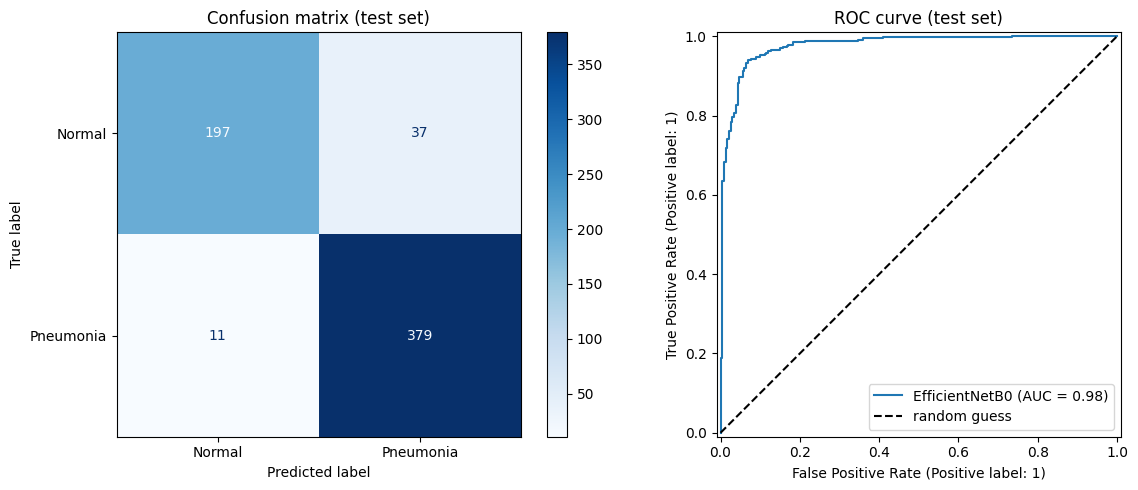

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES,
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="EfficientNetB0")
axes[1].plot([0, 1], [0, 1], "k--", label="random guess"); axes[1].legend()
axes[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.savefig("results/confusion_matrix_roc.png", dpi=120); plt.show()

## 8. Explain predictions with Grad-CAM

Grad-CAM highlights the regions that pushed the model towards "Pneumonia". A good model should focus **inside the lungs**. If it focuses on text labels or image borders, it is using shortcuts — that's an important finding to write about in your README!

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


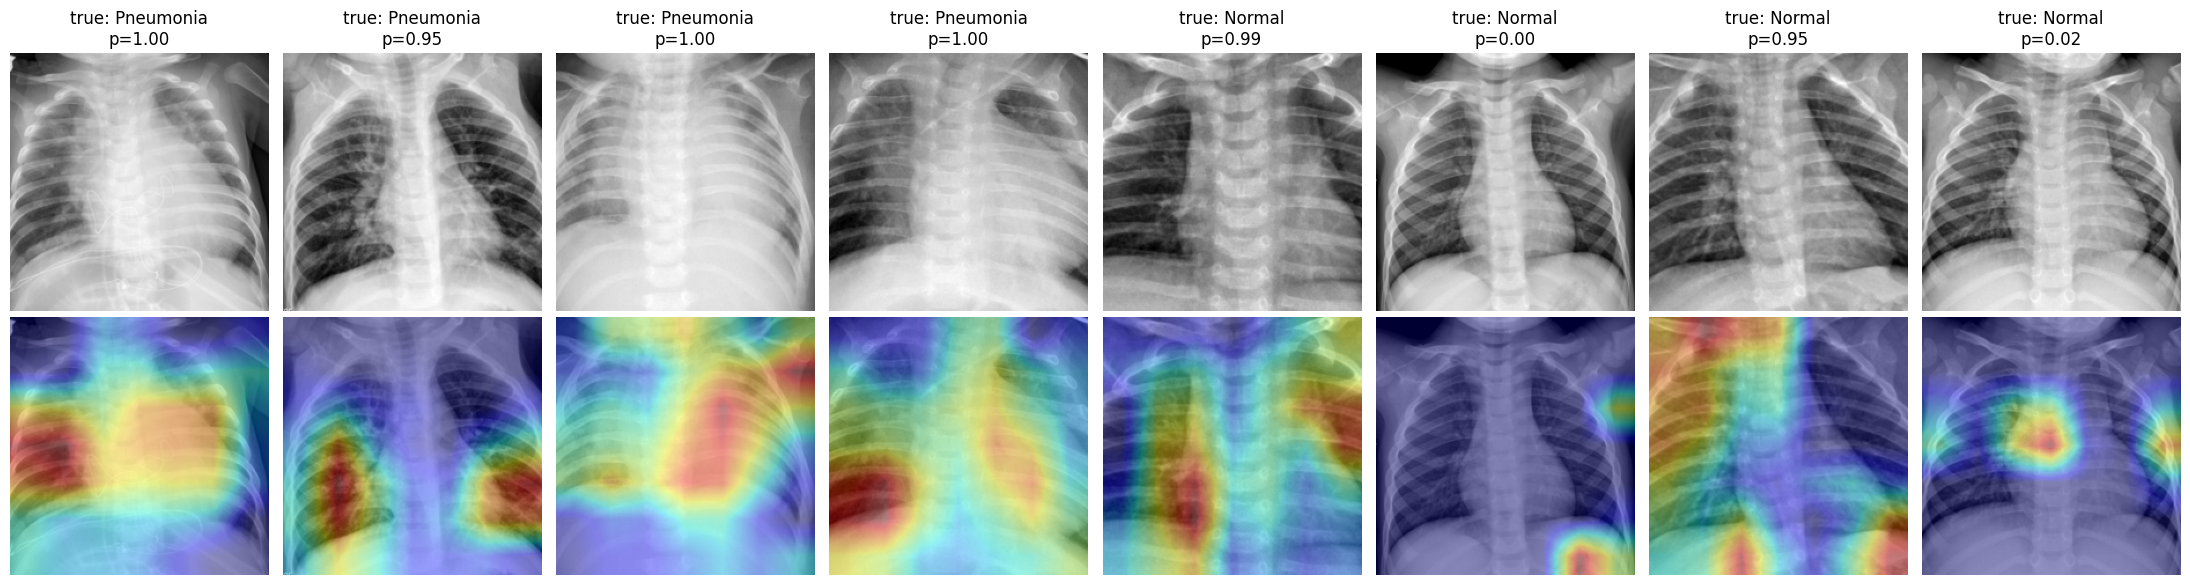

In [12]:
def make_gradcam_heatmap(img_batch, model, last_conv_layer_name="top_activation"):
    grad_model = tf.keras.Model(model.inputs,
                                [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_output, preds = grad_model(img_batch)
        score = preds[:, 0]
    grads = tape.gradient(score, conv_output)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

# Show 4 pneumonia and 4 normal test images
examples = list(np.where(y_test == 1)[0][:4]) + list(np.where(y_test == 0)[0][:4])
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for col, i in enumerate(examples):
    img = X_test[i]
    batch = np.stack([img] * 3, axis=-1).astype("float32")[np.newaxis]
    heatmap = make_gradcam_heatmap(batch, best_model)
    heatmap_big = tf.image.resize(heatmap[..., np.newaxis], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    axes[0, col].imshow(img, cmap="gray"); axes[0, col].axis("off")
    axes[0, col].set_title(f"true: {CLASS_NAMES[y_test[i]]}\np={y_prob[i]:.2f}")
    axes[1, col].imshow(img, cmap="gray"); axes[1, col].imshow(heatmap_big, cmap="jet", alpha=0.4)
    axes[1, col].axis("off")
plt.tight_layout(); plt.savefig("results/gradcam_examples.png", dpi=120); plt.show()

## 9. Save the model for the web app

The best model is already saved as `models/pneumonia_model.keras`. Download it (and the `results/` images for your README) to your computer.

Also save a few test images so you can try the web app.

In [13]:
from PIL import Image
os.makedirs("sample_images", exist_ok=True)
for k, i in enumerate(list(np.where(y_test == 1)[0][:3]) + list(np.where(y_test == 0)[0][:3])):
    Image.fromarray(X_test[i]).save(f"sample_images/test_{k}_{CLASS_NAMES[y_test[i]].lower()}.png")

!zip -qr project_outputs.zip models results sample_images
try:
    from google.colab import files
    files.download("project_outputs.zip")
except ImportError:
    print("Not in Colab — files are in the models/, results/ and sample_images/ folders.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>